In [2]:
import numpy as np 
import matplotlib.pyplot as plt
from hcipy import *
import os
import sys

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from adcFitter_onsky import AdcFitter

In [ ]:
fieldcube = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/unsats/comparison_sweep.fits')

In [4]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle)

In [5]:
filtered_cube = []

for i, field in enumerate(fieldcube):
    filtered = ADC.crop_image(field,mask_diam=0) 
    filtered_cube.append(filtered)

imshow_field(filtered_cube[0])

KeyboardInterrupt: 

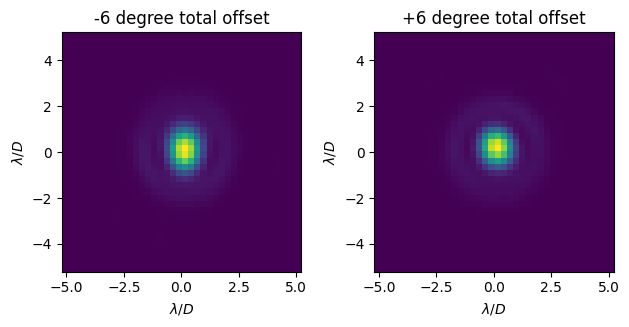

In [ ]:
#measure the FWHM of every image, then average that to get the mean value for this ADC position
#most of this is pulled verbatim from /previous_onsky/gaussian_fwhm.ipynb

img = filtered_cube[50]

peak = np.argmax(img)
window_center = img.grid.points[peak]

pup = ADC.window_field(img,window_center,40,40) #this got its name because i first did it on pipup b
slice = pup.shaped[:,20]

img2 = filtered_cube[-50]

peak2 = np.argmax(img)
window_center2 = img.grid.points[peak2]

pup2 = ADC.window_field(img2,window_center2,40,40) #this got its name because i first did it on pipup b
slice2 = pup2.shaped[:,20]

plt.figure()

plt.subplot(1,2,1)
imshow_field((pup),cmap='viridis')
plt.title('-6 degree total offset')
plt.xlabel(r'$\lambda /D$')
plt.ylabel(r'$\lambda /D$')
#plt.colorbar()

plt.subplot(1,2,2)
plt.title('+6 degree total offset')
imshow_field((pup2),cmap='viridis')
plt.xlabel(r'$\lambda /D$')
plt.ylabel(r'$\lambda /D$')
#plt.colorbar()

plt.tight_layout()
plt.show()


4.723868709171424


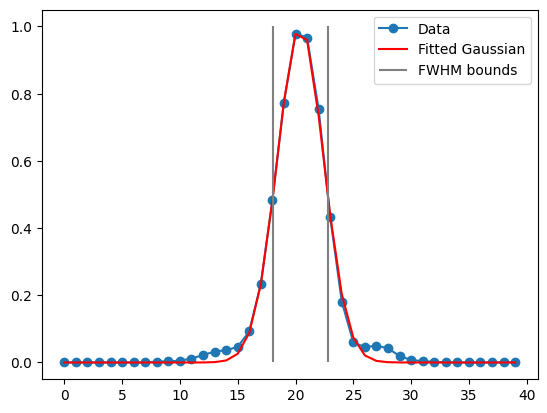

In [10]:
#start from the peak value and scan through the gradient outwards, find where the gradient switches direction. truncate the data there.
from scipy.optimize import curve_fit


def gauss(x,mu,sigma2):
    return np.exp(-(x-mu)**2 / (2 * sigma2) )

def isolate_gaussian(data):
    mid = np.argmax(data)
    first_derivative = np.gradient(data) 

    valley_indices = np.where((first_derivative[:-1] < 0) & (first_derivative[1:] > 0))[0] + 1

    left_valley = valley_indices[valley_indices < mid][-1] if any(valley_indices < mid) else None
    right_valley = valley_indices[valley_indices > mid][0] if any(valley_indices > mid) else None

    if left_valley is not None:
        data[0:left_valley] = 0
        #right_valley -= left_valley

    if right_valley is not None:
        data[right_valley:len(data)-1] = 0
        #print(right_valley)

    return data

def fwhm(data):
    isolated = isolate_gaussian(data)
    x = np.arange(40)
    popt = curve_fit(gauss,x,isolated,p0 = [20,4])

    mu = popt[0][0]
    sigma = popt[0][1]
    fwhm = 2 * np.sqrt(2 * np.log(2)) * np.sqrt(sigma)
    return fwhm, mu, sigma
    

width, mean, sd = fwhm(slice)
x = np.arange(40)
print(width)

s = isolate_gaussian(slice)

plt.figure()
plt.plot(s,'-o',label='Data')
plt.plot(x,gauss(x,mean,sd),'r-',label='Fitted Gaussian')
plt.vlines(mean - width/2,0,1,'gray',label='FWHM bounds')
plt.vlines(mean + width/2,0,1,'gray')
plt.legend()
plt.show()

In [61]:
widths = []

for img in filtered_cube:
    peak = np.argmax(img)
    window_center = img.grid.points[peak]

    pup = ADC.window_field(img,window_center,40,40)
    slice_column = np.array(np.unravel_index(np.argmax(pup),(40,40)))[0]
    slice = pup.shaped[:,slice_column]

    width, mean, sd = fwhm(slice)
    widths.append(width)

widths = np.array(widths)

Text(0.5, 1.0, 'time series of sweep')

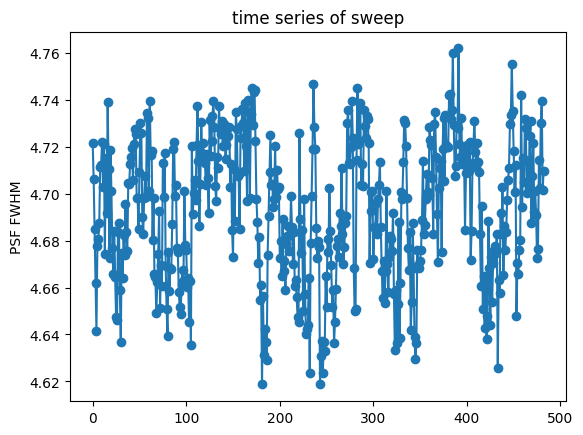

In [108]:
plt.plot(widths[5260:-1],'-o')
plt.ylabel('PSF FWHM')
plt.title('time series of sweep')

In [149]:
minus3 = widths[0:825]
minus2_5 = widths[880:1325]
minus2 = widths[1380:1825]
minus1_5 = widths[1880:2300]
minus1 = widths[2360:2750]
nope = np.zeros(10)
zero = widths[2800:3200]
plus1 = widths[3300:3800]
plus1_5 = widths[4000:4250]
plus2 = widths[4325:4800]
plus2_5 = widths[4900:5200]
plus3 = widths[5260:-1]

steps = [minus3, minus2_5, minus2, minus1_5, minus1, nope, zero, nope, plus1, plus1_5, plus2, plus2_5, plus3]

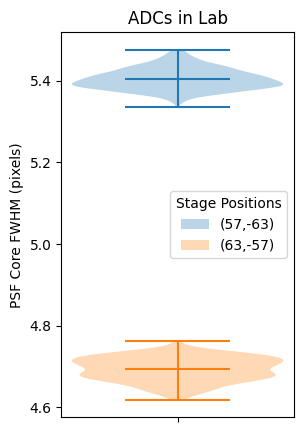

In [150]:
plt.figure(figsize=(3,5))
vp1 = plt.violinplot(minus3,showmeans=True)
vp2 = plt.violinplot(plus3,showmeans=True)
plt.legend([vp1['bodies'][0],vp2['bodies'][0]], ['(57,-63)', '(63,-57)'],title='Stage Positions')
plt.ylabel('PSF Core FWHM (pixels)')
plt.xticks([1],labels=[''])
plt.title('ADCs in Lab')
plt.show()

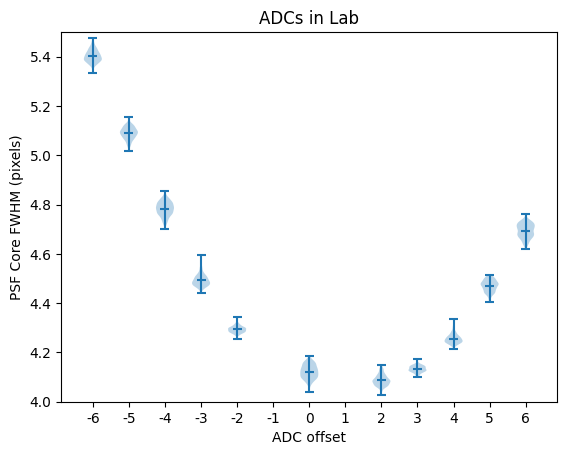

In [155]:
plt.figure()
offsets = [-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6]

vp = plt.violinplot(steps,showmeans=True)


plt.ylabel('PSF Core FWHM (pixels)')
plt.xticks(np.arange(1,14),labels=offsets)
plt.xlabel('ADC offset')
plt.title('ADCs in Lab')
plt.ylim((4,5.5))
plt.show()

In [175]:
#blown up version of the interval from -2 to 2

usatm1 = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/unsats/7725_m1offset.fits')
usatm05 = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/unsats/7725_m05offset.fits')
usatm03 = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/unsats/7725_m03offset.fits')
usatm01 = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/unsats/7725_m01offset.fits')
usat0 = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/unsats/7725_0offset.fits')
usat01 = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/unsats/7725_01offset.fits')
usat03 = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/unsats/7725_03offset.fits')
usat05 = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/unsats/7725_05offset.fits')
usat1 = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/unsats/7725_1offset.fits')

steps = [usatm1,usatm05,usatm03,usatm01,usat0,usat01,usat01,usat03,usat05,usat1]


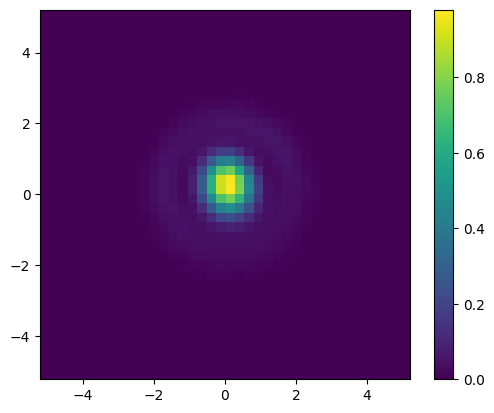

In [176]:
img = usatm1[0]
img = ADC.crop_image(field,mask_diam=0) 

peak = np.argmax(img)
window_center = img.grid.points[peak]

pup = ADC.window_field(img,window_center,40,40) #this got its name because i first did it on pipup b
slice = pup.shaped[:,20]

plt.figure()
imshow_field(pup)
plt.colorbar()
plt.show()

4.723868709171424


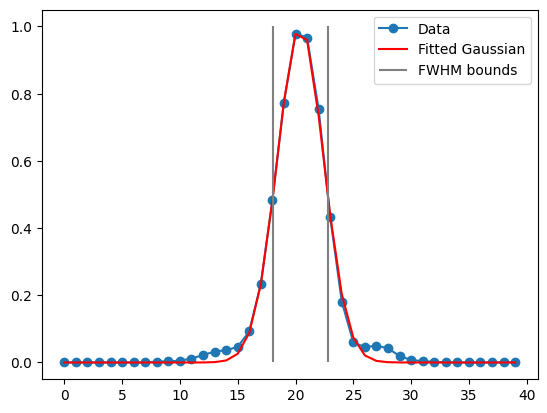

In [177]:
width, mean, sd = fwhm(slice)
x = np.arange(40)
print(width)

s = isolate_gaussian(slice)

plt.figure()
plt.plot(s,'-o',label='Data')
plt.plot(x,gauss(x,mean,sd),'r-',label='Fitted Gaussian')
plt.vlines(mean - width/2,0,1,'gray',label='FWHM bounds')
plt.vlines(mean + width/2,0,1,'gray')
plt.legend()
plt.show()

In [178]:
widths = []
step_widths =[]

for step in steps:
    for img in step:
        img = ADC.crop_image(img,mask_diam=0) 
        peak = np.argmax(img)
        window_center = img.grid.points[peak]

        pup = ADC.window_field(img,window_center,40,40)
        slice_column = np.array(np.unravel_index(np.argmax(pup),(40,40)))[0]
        slice = pup.shaped[:,slice_column]

        width, mean, sd = fwhm(slice)
        widths.append(width)
    step_widths.append(widths)
    widths = []


Text(0.5, 1.0, 'ADCs in Lab')

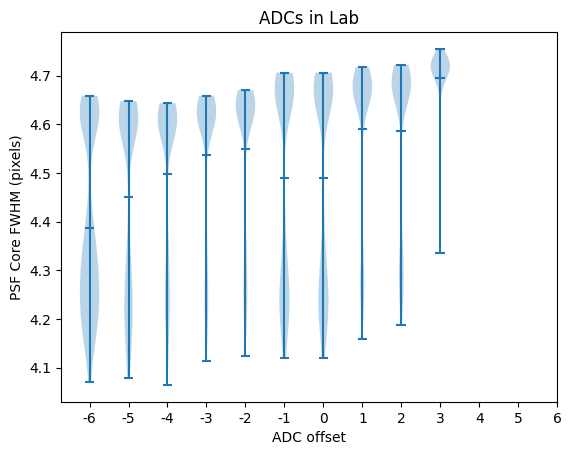

In [179]:
plt.figure()
offsets = [-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6]

vp = plt.violinplot(step_widths,showmeans=True)


plt.ylabel('PSF Core FWHM (pixels)')
plt.xticks(np.arange(1,14),labels=offsets)
plt.xlabel('ADC offset')
plt.title('ADCs in Lab')

In [14]:
#yet another version
fieldcube = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/unsats/finer_sweep.fits')

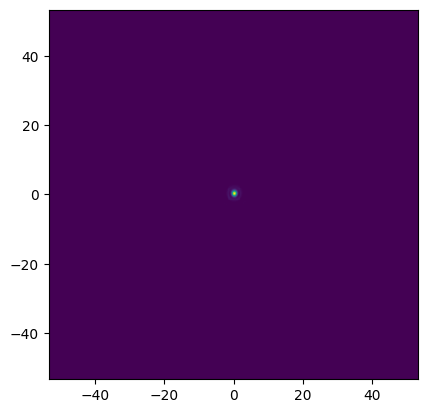

In [15]:
filtered_cube = []

for i, field in enumerate(fieldcube):
    filtered = ADC.crop_image(field,mask_diam=0) 
    filtered_cube.append(filtered)

imshow_field(filtered_cube[0])

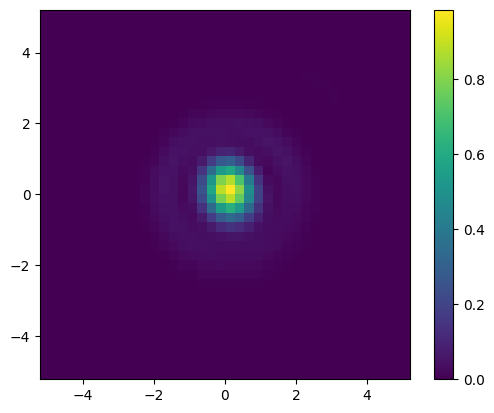

In [16]:
img = filtered_cube[0]
img = ADC.crop_image(field,mask_diam=0) 

peak = np.argmax(img)
window_center = img.grid.points[peak]

pup = ADC.window_field(img,window_center,40,40) #this got its name because i first did it on pipup b
slice = pup.shaped[:,20]

plt.figure()
imshow_field(pup)
plt.colorbar()
plt.show()

4.6579662390169965


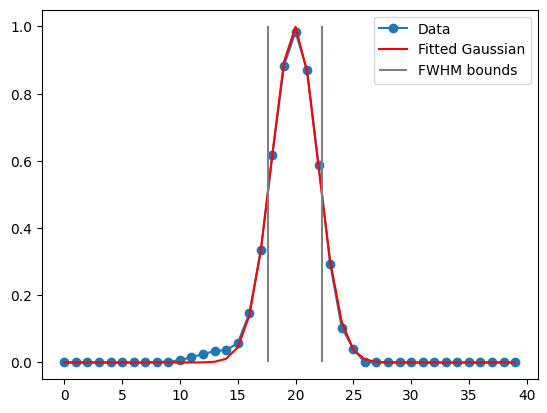

In [17]:
width, mean, sd = fwhm(slice)
x = np.arange(40)
print(width)

s = isolate_gaussian(slice)

plt.figure()
plt.plot(s,'-o',label='Data')
plt.plot(x,gauss(x,mean,sd),'r-',label='Fitted Gaussian')
plt.vlines(mean - width/2,0,1,'gray',label='FWHM bounds')
plt.vlines(mean + width/2,0,1,'gray')
plt.legend()
plt.show()

In [18]:
#now to isolate the steps
widths = []

for img in filtered_cube:
    peak = np.argmax(img)
    window_center = img.grid.points[peak]

    pup = ADC.window_field(img,window_center,40,40)
    slice_column = np.array(np.unravel_index(np.argmax(pup),(40,40)))[0]
    slice = pup.shaped[:,slice_column]

    width, mean, sd = fwhm(slice)
    widths.append(width)

widths = np.array(widths)

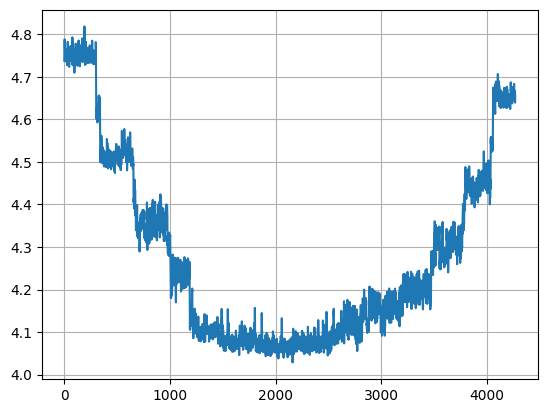

In [46]:
plt.plot(widths)
plt.xlim()
plt.grid()

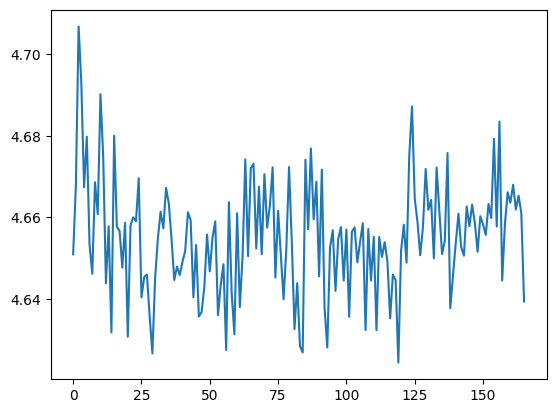

In [73]:
#now to separate out each of the steps (there are 14 and they are not equally spaced)
plt.plot(widths[4100:-1])

In [75]:
minus4 = widths[0:300]
minus3 = widths[350:650]
minus2 = widths[700:950]
minus1 = widths[1060:1180]
zero = widths[1250:1450]
plus0_5 = widths[1475:1750]
plus1 = widths[1820:2150]
plus1_5 = widths[2150:2350]
plus2 = widths[2600:2800]
plus2_5 = widths[2800:3200]
plus3 = widths[3200:3450]
plus4 = widths[3500:3750]
plus5 = widths[3800:4000]
plus6 = widths[4100:-1]


steps = [minus4,minus3,minus2,minus1,zero,plus0_5,plus1,plus1_5,plus2,plus2_5,plus3,plus4,plus5,plus6]

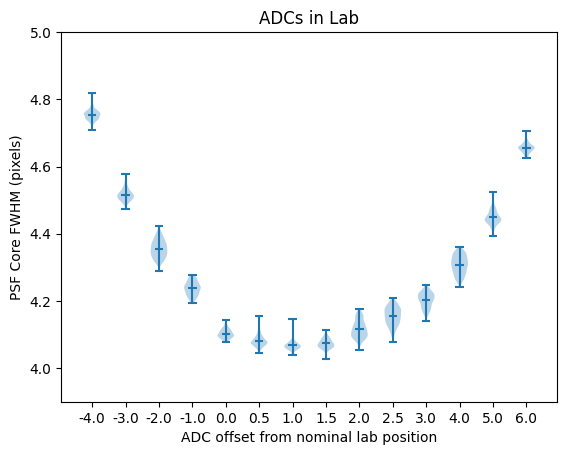

In [96]:
plt.figure()
offsets = np.array([-4,-3,-2,-1,0,0.5,1,1.5,2,2.5,3,4,5,6])

vp = plt.violinplot(steps,showmeans=True)


plt.ylabel('PSF Core FWHM (pixels)')
plt.xticks(np.arange(1,15),labels=offsets)
plt.xlabel('ADC offset from nominal lab position')
plt.title('ADCs in Lab')
plt.ylim((3.9,5))
plt.show()

[4.75398611 4.51547623 4.35544425 4.23770562 4.10284854 4.08216836
 4.06764879 4.07350171 4.1169017  4.15448283 4.20235881 4.30748251
 4.44869789 4.65503957]


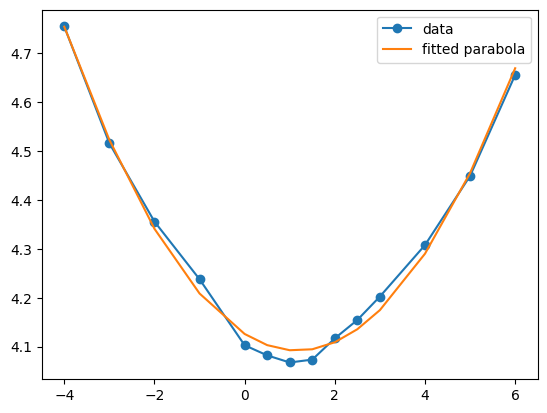

1.0


In [101]:
#averaging each step and then fitting a parabola to it so i can find the vertex
steps_avgs = np.array([np.mean(step) for step in steps])
print(steps_avgs)
plt.plot(offsets,steps_avgs,'-o',label='data')

fit = np.polyfit(offsets,steps_avgs,2)
parabola = fit[0] * offsets**2 + fit[1] * offsets + fit[2]

plt.plot(offsets, parabola,label='fitted parabola')
plt.legend()
plt.show()

print(offsets[np.argmin(parabola)])